# Pollution along the growth path, with night lights: G2

Step 1 of the pollution follow-up (`docs/successors/pollution-lights-prespec.md`). This notebook runs the coverage gate G2 and the purpose rule G2b. **It loads no PM2.5**: the region panel has only a count of the 10 km cells with PM2.5.

Since the 2026-10-30 change log, the main sample is the DMSP years 1998–2012, and 1 km cells within 5 km of an upstream gas flare are left out of lights and population. The first G2 run (1998–2022, no flare mask) is recorded in the pre-spec's §5. The splice cell at the end shows why the years changed.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('../..'))
os.chdir(os.path.abspath('../..'))
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, pyfixest as pf
import src.analysis.pollution_lights as pl
d = pl.build_lights_panel()
print(d.GID_1.nunique(), 'regions,', d.GID_0.nunique(), 'countries,', d.year.min(), '-', d.year.max())

3429 regions, 235 countries, 1998 - 2022


## Sample construction (§2): main sample, 1998–2012

In [2]:
m = d[d.year.between(*pl.MAIN_YEARS)]
small = m.n_cells.lt(pl.MIN_CELLS)
nopop = m['pop'].isna() | m['pop'].le(0)
zero = ~small & ~nopop & m.lights.eq(0)
print('region-years below 5 cells:', small.sum(), 'in', m.loc[small, 'GID_1'].nunique(), 'regions')
print('without population:', nopop.sum(), 'in', m.loc[nopop, 'GID_1'].nunique(), 'regions')
print('zero lights (dropped):', zero.sum(), 'in', m.loc[zero, 'GID_1'].nunique(), 'regions')
print('  by country:', m[zero].groupby('GID_0').size().sort_values(ascending=False).head(10).to_dict())
nt = m[~small & m.tercile.isna()]
print('no V-Dem baseline:', nt.GID_0.nunique(), 'countries,', nt.GID_1.nunique(), 'regions')
s = pl.sample(d)
print('sample:', len(s), 'region-years,', s.GID_1.nunique(), 'regions,', s.GID_0.nunique(), 'countries')

region-years below 5 cells: 6540 in 436 regions
without population: 345 in 23 regions
zero lights (dropped): 1470 in 254 regions
  by country: {'UGA': 322, 'BDI': 93, 'MHL': 89, 'AFG': 80, 'BTN': 80, 'SLB': 79, 'CAF': 77, 'LBR': 70, 'TCD': 58, 'COD': 46}
no V-Dem baseline: 42 countries, 141 regions
sample: 41570 region-years, 2840 regions, 169 countries


## Gas flares

The share of each country's lights that the flare mask removes (main sample).

In [3]:
f = m.groupby('GID_0')[['lights', 'lights_flare']].sum()
f['flare_share'] = f.lights_flare / (f.lights + f.lights_flare)
print('global share masked: %.3f' % (f.lights_flare.sum() / (f.lights + f.lights_flare).sum()))
print(f.flare_share.sort_values(ascending=False).head(12).round(3).to_dict())

global share masked: 0.037
{'BHR': 0.529, 'GAB': 0.463, 'KWT': 0.327, 'NGA': 0.267, 'IRQ': 0.267, 'COG': 0.25, 'QAT': 0.197, 'OMN': 0.179, 'LBY': 0.179, 'PNG': 0.167, 'DZA': 0.167, 'TCD': 0.16}


## Knots (§3)

On the main sample's DOSE-matched region-years (1998–2012): ln lights per person on ln output per person, year FE. If the within-year R² is below 0.5, the knots are the sample quartiles (each region weighted equally).

In [4]:
k = pl.calibrate_knots(s)
print({x: v for x, v in k.items() if x != 'knots'})
print('rule:', k['rule'])
print('knots (ln lights per person):', k['knots'].round(3))
c = s[s.y_usd.gt(0)].assign(log_y=lambda x: np.log(x.y_usd))
fe = {int(float(a)): v for a, v in pf.feols('log_lpc ~ log_y | year', data=c).fixef()['C(year)'].items()}[k['mean_year']]
print('income at the knots, by the calibration (information):', np.exp((k['knots'] - fe) / k['slope']).round(-1))

{'rule': 'DOSE calibration', 'slope': 0.7185549552498264, 'r2_within': 0.5420254766697274, 'n': 18697, 'regions': 1494, 'mean_year': 2005}
rule: DOSE calibration
knots (ln lights per person): [-4.017 -3.02  -2.231]


income at the knots, by the calibration (information): [ 1000.  4000. 12000.]


## ◇ G2 coverage and ◇ G2b purpose (§4)

In [5]:
r = pl.g2(s, k['knots'])
print(r['by_tercile'], '\n')
print('regions per tercile x segment:'); print(r['regions'], '\n')
print('comparisons:', r['comparisons'])
print('G2 passes:', r['g2_passes'])
print('G2b: high tercile in the lowest segment:', r['g2b_high_seg0'], 'regions; passes:', r['g2b_passes'])

         countries  regions  passes
tercile                            
0.0             56      817    True
1.0             56     1195    True
2.0             57      828    True 

regions per tercile x segment:
         seg0  seg1  seg2  seg3
tercile                        
0         515   225   196   149
1         649   485   442   219
2         103   219   355   471 

comparisons: [('seg0', 0, 1), ('seg0', 1, 2), ('seg1', 0, 1), ('seg1', 1, 2), ('seg2', 0, 1), ('seg2', 1, 2), ('seg3', 0, 1), ('seg3', 1, 2)]
G2 passes: True
G2b: high tercile in the lowest segment: 103 regions; passes: True


In [6]:
seg = s.assign(segment=pl.segment(s.log_lpc, k['knots']))
h = seg[(seg.tercile == 2) & (seg.segment == 0)]
print('high x lowest segment, regions by country:', h.groupby('GID_0').GID_1.nunique().sort_values(ascending=False).to_dict())
l = seg[(seg.tercile == 0) & (seg.segment == 3)]
print('low x highest segment:', l.GID_0.nunique(), 'countries; top:', l.groupby('GID_0').GID_1.nunique().sort_values(ascending=False).head(8).to_dict())

high x lowest segment, regions by country: {'IND': 26, 'MNG': 14, 'SEN': 14, 'DOM': 13, 'PAN': 7, 'BOL': 6, 'NAM': 4, 'CPV': 3, 'KOR': 3, 'JPN': 3, 'EST': 2, 'SUR': 2, 'ECU': 1, 'GRC': 1, 'NZL': 1, 'NOR': 1, 'TWN': 1, 'VEN': 1}
low x highest segment: 21 countries; top: {'IRN': 23, 'SRB': 22, 'LBY': 21, 'SAU': 13, 'KAZ': 11, 'OMN': 11, 'TUN': 7, 'EGY': 7}


## Information: the sensor splice (all years 1998–2022)

`ntl_harm` splices DMSP (to 2013) and VIIRS (from 2014). Year FE absorb a jump only if it is the same in log terms everywhere. This is why the main sample stops in 2012.

In [7]:
w = d[d.n_cells.ge(pl.MIN_CELLS)].pivot(index='GID_1', columns='year', values='lights').where(lambda x: x > 0)
quintile = pd.qcut(np.log(w[2012]), 5, labels=['dimmest', '2', '3', '4', 'brightest'])
jumps = pd.DataFrame({
    '2013 vs mean(2012, 2014)': np.log(w[2013]) - np.log((w[2012] + w[2014]) / 2),
    '2012 -> 2014': np.log(w[2014]) - np.log(w[2012]),
    '2016 -> 2017': np.log(w[2017]) - np.log(w[2016]),
})
print('median log change by 2012 brightness quintile:')
print(jumps.groupby(quintile).median().round(2))
print('global sum by year (millions DN):', (d[d.n_cells.ge(pl.MIN_CELLS)].groupby('year').lights.sum() / 1e6).round(0).astype(int).to_dict())

median log change by 2012 brightness quintile:
           2013 vs mean(2012, 2014)  2012 -> 2014  2016 -> 2017
2012                                                           
dimmest                        2.27         -0.52          0.65
2                              1.25         -0.39          0.49
3                              0.59         -0.33          0.41
4                              0.30         -0.27          0.32
brightest                      0.12         -0.30          0.26
global sum by year (millions DN): {1998: 272, 1999: 276, 2000: 300, 2001: 294, 2002: 294, 2003: 290, 2004: 306, 2005: 300, 2006: 283, 2007: 313, 2008: 305, 2009: 319, 2010: 340, 2011: 334, 2012: 353, 2013: 483, 2014: 277, 2015: 274, 2016: 269, 2017: 360, 2018: 368, 2019: 383, 2020: 397, 2021: 461, 2022: 476}


## Main specification (§3): the first PM2.5 load

ln PM2.5 (region mean of its 10 km cells) on a piecewise-linear spline in ln lights per person at the calibrated knots (1,000 / 4,000 / 12,000 USD), interacted with baseline `v2x_polyarchy` terciles; region FE and tercile × year FE; no weather controls; clusters by country; no weights. Support (≥ 50 regions) and the comparisons are recomputed on the regression rows.

In [8]:
import src.analysis.pollution as P
p = pl.add_pm25(s, k['knots'])
print(len(p), 'region-years,', p.GID_1.nunique(), 'regions,', p.GID_0.nunique(), 'countries (', len(s) - len(p), 'rows without PM2.5 )')
n = P.supported_cells(p)
n.columns = P.SEGMENT_LABELS
print(n, '\n')
print('comparisons:', P.comparisons(P.supported_cells(p)))

41570 region-years, 2840 regions, 169 countries ( 0 rows without PM2.5 )
         < 1,000  1,000-4,000  4,000-12,000  > 12,000
tercile                                              
0.0          515          225           196       149
1.0          649          485           442       219
2.0          103          219           355       471 

comparisons: [('seg0', 0, 1), ('seg0', 1, 2), ('seg1', 0, 1), ('seg1', 1, 2), ('seg2', 0, 1), ('seg2', 1, 2), ('seg3', 0, 1), ('seg3', 1, 2)]


In [9]:
main = P.fit_paths(p, controls=())
print('N =', main['n'])
main['slopes'].round(4)

N = 41557


,segment,group,regions,supported,est,se,p
0,"< 1,000",0,515,True,0.0173,0.0100,0.0847
1,"< 1,000",1,649,True,-0.0047,0.0146,0.7457
2,"< 1,000",2,103,True,0.0516,0.0263,0.0514
3,"1,000-4,000",0,225,True,-0.0296,0.0416,0.4770
4,"1,000-4,000",1,485,True,-0.0108,0.0269,0.6897
5,"1,000-4,000",2,219,True,0.1282,0.0587,0.0302
6,"4,000-12,000",0,196,True,-0.1103,0.0461,0.0178
7,"4,000-12,000",1,442,True,-0.0418,0.0471,0.3765
8,"4,000-12,000",2,355,True,0.0038,0.0323,0.9060
9,"> 12,000",0,149,True,-0.0637,0.0281,0.0246


### ◇ Moderation: the supported comparisons and their joint Wald test

In [10]:
print(main['wald'])
main['diffs'].round(4)

{'F': 2.057277762296829, 'q': 8, 'df2': 168, 'p': 0.04269691226343559}


,segment,comparison,diff,se,p
0,"< 1,000",1 - 0,-0.0221,0.0177,0.2136
1,"< 1,000",2 - 1,0.0563,0.0300,0.0627
2,"1,000-4,000",1 - 0,0.0189,0.0496,0.7037
3,"1,000-4,000",2 - 1,0.1390,0.0645,0.0327
4,"4,000-12,000",1 - 0,0.0686,0.0659,0.2999
5,"4,000-12,000",2 - 1,0.0456,0.0572,0.4260
6,"> 12,000",1 - 0,-0.0149,0.0441,0.7364
7,"> 12,000",2 - 1,0.1210,0.0506,0.0179


### Information: region clusters

In [11]:
reg = P.fit_paths(p, controls=(), vcov={'CRV1': 'GID_1'})
print(reg['wald'])
reg['diffs'].round(4)

{'F': 11.249781909530004, 'q': 8, 'df2': 168, 'p': 1.0769782511834026e-12}


,segment,comparison,diff,se,p
0,"< 1,000",1 - 0,-0.0221,0.0069,0.0018
1,"< 1,000",2 - 1,0.0563,0.0156,0.0004
2,"1,000-4,000",1 - 0,0.0189,0.0253,0.4569
3,"1,000-4,000",2 - 1,0.1390,0.0306,0.0000
4,"4,000-12,000",1 - 0,0.0686,0.0278,0.0145
5,"4,000-12,000",2 - 1,0.0456,0.0233,0.0517
6,"> 12,000",1 - 0,-0.0149,0.0278,0.5937
7,"> 12,000",2 - 1,0.1210,0.0211,0.0000


## Pooled path (one spline, region + year FE, country clusters)

In [12]:
pooled = P.fit_pooled(p, controls=())
pooled['slopes'].round(4)

,Estimate,Std. Error,Pr(>|t|)
"< 1,000",0.0182,0.0096,0.0586
"1,000-4,000",0.0203,0.0199,0.3082
"4,000-12,000",-0.0421,0.0311,0.1772
"> 12,000",-0.0181,0.0276,0.5140


## Variants 1, 2 and H (needed for the moderation and turning-point rules)

1. + country-specific linear trends; 2. country × year FE instead of tercile × year FE; H. regions in the lower two terciles of baseline (1998–2000) mean PM2.5, cutoffs across regions (haze guard, §4). Support is recomputed in H.

In [13]:
p1, trends = P.add_country_trends(p)
v1 = P.fit_paths(p1, controls=(), extra=trends)
v2 = P.fit_paths(p, controls=(), fe='GID_1 + GID_0^year')
ph, hcuts = pl.low_haze(p)
vh = P.fit_paths(ph, controls=())
print('H: baseline PM2.5 cutoffs (ug/m3):', hcuts.round(2), '|', len(ph), 'region-years,', ph.GID_1.nunique(), 'regions,', ph.GID_0.nunique(), 'countries')
nh = P.supported_cells(ph); nh.columns = P.SEGMENT_LABELS
print(nh)
for name, r in {'variant 1': v1, 'variant 2': v2, 'variant H': vh}.items():
    print(name, {a: round(b, 4) for a, b in r['wald'].items()})

H: baseline PM2.5 cutoffs (ug/m3): [11.89 18.44] | 27561 region-years, 1860 regions, 135 countries
         < 1,000  1,000-4,000  4,000-12,000  > 12,000
tercile                                              
0.0          181          106            91        33
1.0          425          372           360       183
2.0           63          186           304       405
variant 1 {'F': 1.6295, 'q': 8, 'df2': 168, 'p': 0.1198}
variant 2 {'F': 2.5061, 'q': 8, 'df2': 168, 'p': 0.0135}
variant H {'F': 4.5948, 'q': 7, 'df2': 134, 'p': 0.0001}


In [14]:
key = ['segment', 'comparison']
signs = main['diffs'][key + ['diff', 'p']].rename(columns={'diff': 'main', 'p': 'p_main'})
for name, r in {'v1': v1, 'v2': v2, 'H': vh}.items():
    signs = signs.merge(r['diffs'][key + ['diff', 'p']].rename(columns={'diff': name, 'p': f'p_{name}'}), on=key, how='left')
signs.round(4)

,segment,comparison,main,p_main,v1,p_v1,v2,p_v2,H,p_H
0,"< 1,000",1 - 0,-0.0221,0.2136,-0.0049,0.6184,-0.0058,0.2985,-0.0349,0.1410
1,"< 1,000",2 - 1,0.0563,0.0627,0.0050,0.6555,0.0109,0.1272,0.0642,0.0148
2,"1,000-4,000",1 - 0,0.0189,0.7037,0.0465,0.1047,0.0327,0.1818,0.0563,0.3270
3,"1,000-4,000",2 - 1,0.1390,0.0327,0.0282,0.4204,0.0183,0.3705,0.2054,0.0030
4,"4,000-12,000",1 - 0,0.0686,0.2999,0.0609,0.1431,0.0465,0.0583,0.1611,0.0310
5,"4,000-12,000",2 - 1,0.0456,0.4260,-0.0485,0.2734,-0.0480,0.1072,0.0621,0.3033
6,"> 12,000",1 - 0,-0.0149,0.7364,-0.0023,0.9611,0.0089,0.7229,NaN,NaN
7,"> 12,000",2 - 1,0.1210,0.0179,0.0769,0.0075,0.0411,0.0153,0.1019,0.0414


In [15]:
pd.concat({'variant 1': v1['slopes'], 'variant 2': v2['slopes'], 'variant H': vh['slopes']}).round(4)

segment  group  regions  supported     est      se       p
variant 1 0        < 1,000      0      515       True  0.0025  0.0061  0.6805
          1        < 1,000      1      649       True -0.0023  0.0076  0.7585
          2        < 1,000      2      103       True  0.0027  0.0083  0.7463
          3    1,000-4,000      0      225       True -0.0357  0.0259  0.1710
          4    1,000-4,000      1      485       True  0.0109  0.0118  0.3608
          5    1,000-4,000      2      219       True  0.0390  0.0328  0.2360
          6   4,000-12,000      0      196       True -0.0427  0.0332  0.1996
          7   4,000-12,000      1      442       True  0.0182  0.0248  0.4637
          8   4,000-12,000      2      355       True -0.0303  0.0365  0.4079
          9       > 12,000      0      149       True  0.0058  0.0433  0.8935
          10      > 12,000      1      219       True  0.0035  0.0172  0.8372
          11      > 12,000      2      471       True  0.0804  0.0226  0.0005
variant 2 0        < 1,000      0      515       True  0.0032  0.0029  0.2750
          1        < 1,000      1      649       True -0.0027  0.0048  0.5787
          2        < 1,000      2      103       True  0.0082  0.0053  0.1198
          3    1,000-4,000      0      225       True -0.0212  0.0228  0.3523
          4    1,000-4,000      1      485       True  0.0115  0.0088  0.1935
          5    1,000-4,000      2      219       True  0.0298  0.0184  0.1075
          6   4,000-12,000      0      196       True -0.0325  0.0204  0.1122
          7   4,000-12,000      1      442       True  0.0140  0.0134  0.2993
          8   4,000-12,000      2      355       True -0.0340  0.0264  0.1997
          9       > 12,000      0      149       True -0.0187  0.0239  0.4354
          10      > 12,000      1      219       True -0.0098  0.0071  0.1660
          11      > 12,000      2      471       True  0.0312  0.0152  0.0413
variant H 0        < 1,000      0      181       True  0.0277  0.0142  0.0539
          1        < 1,000      1      425       True -0.0072  0.0188  0.7015
          2        < 1,000      2       63       True  0.0570  0.0180  0.0019
          3    1,000-4,000      0      106       True -0.1033  0.0478  0.0323
          4    1,000-4,000      1      372       True -0.0470  0.0315  0.1387
          5    1,000-4,000      2      186       True  0.1584  0.0602  0.0095
          6   4,000-12,000      0       91       True -0.2072  0.0537  0.0002
          7   4,000-12,000      1      360       True -0.0461  0.0507  0.3641
          8   4,000-12,000      2      304       True  0.0159  0.0322  0.6223
          9       > 12,000      0       33      False -0.0346  0.0500  0.4905
          10      > 12,000      1      183       True -0.0705  0.0287  0.0155
          11      > 12,000      2      405       True  0.0314  0.0403  0.4364

### ◇ Rules applied

In [16]:
sig = signs[signs.p_main < 0.05]
keeps = all(np.sign(r.main) == np.sign(r[v]) for _, r in sig.iterrows() for v in ('v1', 'v2', 'H'))
print('Wald rejects at 5 %:', main['wald']['p'] < 0.05, '| comparisons different at 5 %:', len(sig),
      '| each keeps its sign in v1, v2, H:', keeps)
print('MODERATION:', 'institutions change the path' if main['wald']['p'] < 0.05 and keeps
      else 'no robust difference between institution groups')
t = main['slopes'].merge(vh['slopes'], on=['segment', 'group'], suffixes=('', '_H'))
t = t[t.supported]
down = t[(t.est < 0) & (t.p < 0.05) & (t.est_H < 0) & (t.p_H < 0.05) & t.supported_H]
print('negative at 5 % in main:', t[(t.est < 0) & (t.p < 0.05)][['segment', 'group']].values.tolist())
print('TURNING POINT (negative at 5 % in main and H):', down[['segment', 'group']].values.tolist() or 'none')
ph_pooled = P.fit_pooled(ph, controls=())
print('pooled path, main and H:')
pd.concat({'main': pooled['slopes'], 'H': ph_pooled['slopes']}, axis=1).round(4)

Wald rejects at 5 %: True | comparisons different at 5 %: 2 | each keeps its sign in v1, v2, H: True
MODERATION: institutions change the path
negative at 5 % in main: [['4,000-12,000', 0], ['> 12,000', 0], ['> 12,000', 1]]
TURNING POINT (negative at 5 % in main and H): [['4,000-12,000', 0], ['> 12,000', 1]]


pooled path, main and H:


main                            H                    
             Estimate Std. Error Pr(>|t|) Estimate Std. Error Pr(>|t|)
< 1,000        0.0182     0.0096   0.0586   0.0212     0.0145   0.1450
1,000-4,000    0.0203     0.0199   0.3082   0.0104     0.0241   0.6666
4,000-12,000  -0.0421     0.0311   0.1772  -0.0315     0.0374   0.4013
> 12,000      -0.0181     0.0276   0.5140  -0.0105     0.0340   0.7587

## Information: the DOSE overlap

On the DOSE-matched region-years of this sample, the lights-path slopes, next to the idea-B main specification (DOSE output, 1998–2018, with `P_a` and `T_a`). The samples differ in years and controls, so the comparison is rough.

In [17]:
pd_ = p[p.y_usd.gt(0)]
lo = P.fit_paths(pd_, controls=())
ib = P.fit_paths(P.sample(P.build_region_panel()))
print('lights on DOSE regions:', len(pd_), 'region-years,', pd_.GID_1.nunique(), 'regions')
cols = ['segment', 'group', 'regions', 'est', 'se']
lo['slopes'][cols].merge(ib['slopes'][cols], on=['segment', 'group'], suffixes=('_lights', '_dose')).round(3)

lights on DOSE regions: 18697 region-years, 1494 regions


,segment,group,regions_lights,est_lights,se_lights,regions_dose,est_dose,se_dose
0,"< 1,000",0,99,0.104,0.059,175,0.118,0.043
1,"< 1,000",1,184,0.046,0.031,83,0.208,0.170
2,"< 1,000",2,58,0.074,0.065,0,NaN,NaN
3,"1,000-4,000",0,110,-0.025,0.053,441,0.058,0.023
4,"1,000-4,000",1,271,0.057,0.022,342,0.063,0.055
5,"1,000-4,000",2,126,0.175,0.108,18,0.710,0.062
6,"4,000-12,000",0,71,-0.180,0.113,221,-0.009,0.059
7,"4,000-12,000",1,304,0.031,0.056,346,-0.051,0.071
8,"4,000-12,000",2,257,0.015,0.041,133,0.118,0.078
9,"> 12,000",0,70,-0.147,0.077,43,-0.022,0.038


## Variants 3–8 (reported, not selected)

Construction details are in the change log (2026-10-30, before variants 3–8). Support and comparisons are recomputed for each grouping or sample by the 50-region rule.

3. Rule of law: baseline `v2x_rule` terciles, with rule-of-law tercile × year FE.
4. Without dusty regions: desert share ≤ 0.5.
5. Population-weighted PM2.5 (GHS-POP weights within the region) with population regression weights; each alone as information.
6. VIIRS years 2014–2022, with knots and terciles set by §3 on those years.
7. ln lights per area (per 10 km cell with PM2.5 and lights), knots by the §3 rule.
8. + GLASS air temperature, 2000–2012.

In [18]:
V = {}
V['3 rule of law'] = P.fit_paths(p, group='tercile_rule', controls=())
V['4 desert share <= 0.5'] = P.fit_paths(p[p.desert_share <= 0.5], controls=())
pw = p[p.log_pm25_popw.notna()]
V['5 pop-weighted PM2.5 + pop weights'] = P.fit_paths(pw, y='log_pm25_popw', weights='pop', controls=())
info5 = {'5a pop-weighted PM2.5 only': P.fit_paths(pw, y='log_pm25_popw', controls=()),
         '5b pop weights only': P.fit_paths(p, weights='pop', controls=())}
print('rows without population-weighted PM2.5:', len(p) - len(pw))

rows without population-weighted PM2.5: 0


### Variant 6: the VIIRS years (knots, terciles and coverage by the same rules)

In [19]:
s6 = pl.sample(d, years=pl.VIIRS_YEARS)
k6 = pl.calibrate_knots(s6)
print({x: v for x, v in k6.items() if x != 'knots'}, '| knots:', k6['knots'].round(3))
g6 = pl.g2(s6, k6['knots'])
print(g6['by_tercile']); print(g6['regions'])
print('tercile changes against the main sample:', (s6.drop_duplicates('GID_0').set_index('GID_0').tercile
      != s.drop_duplicates('GID_0').set_index('GID_0').tercile.reindex(s6.GID_0.unique())).sum(), 'countries')
p6 = pl.add_pm25(s6, k6['knots'])
V['6 VIIRS years 2014-2022'] = P.fit_paths(p6, controls=())
print(len(p6), 'region-years,', p6.GID_1.nunique(), 'regions,', p6.GID_0.nunique(), 'countries')

{'rule': 'quartiles (R2 below 0.5)', 'slope': 0.6405519491410858, 'r2_within': 0.38836454104803964, 'n': 8186, 'regions': 1471, 'mean_year': 2016} | knots: [-4.632 -3.163 -2.215]
         countries  regions  passes
tercile                            
0.0             56      822    True
1.0             56     1198    True
2.0             57      828    True
         seg0  seg1  seg2  seg3
tercile                        
0         390   404   268   197
1         520   587   509   361
2          49   244   518   470
tercile changes against the main sample: 0 countries


25513 region-years, 2848 regions, 169 countries


### Variant 7: lights per area

In [20]:
k7 = pl.calibrate_knots(s, x='log_lpa')
print({x: v for x, v in k7.items() if x != 'knots'}, '| knots:', k7['knots'].round(3))
print(pl.g2(s, k7['knots'], x='log_lpa')['regions'])
p7 = pl.add_pm25(s, k7['knots'], x='log_lpa')
V['7 lights per area'] = P.fit_paths(p7, controls=())

{'rule': 'quartiles (R2 below 0.5)', 'slope': 0.7189597415380983, 'r2_within': 0.2813536904216545, 'n': 18697, 'regions': 1494, 'mean_year': 2005} | knots: [3.035 5.36  6.638]
         seg0  seg1  seg2  seg3
tercile                        
0         370   330   259   175
1         387   568   538   270
2         104   206   276   479


### Variant 8: + GLASS air temperature (2000–2012)

In [21]:
p8 = p[p.year.ge(2000) & p.glass_ta.notna()]
print(len(p8), 'region-years,', p8.GID_1.nunique(), 'regions')
V['8 + GLASS air temperature'] = P.fit_paths(p8, controls=('glass_ta',))

35944 region-years, 2826 regions


### Summary across all variants

For each: the joint Wald test of its supported comparisons, the number of comparisons at 5 %, the comparison above 12,000 USD (high − middle), one of the two that carry the main result, and the two downturn cells (low at 4–12k, middle above 12k).

In [22]:
def row(name, r):
    dd = r['diffs'].set_index(['segment', 'comparison'])
    sl = r['slopes'].set_index(['segment', 'group'])
    out = dict(variant=name, N=r['n'], q=r['wald']['q'], wald_p=r['wald']['p'], n_sig=int((r['diffs'].p < 0.05).sum()))
    kk = ('> 12,000', '2 - 1')
    out['top: high-mid'], out['p'] = (dd.loc[kk, 'diff'], dd.loc[kk, 'p']) if kk in dd.index else (np.nan, np.nan)
    for lab, key in (('low 4-12k', ('4,000-12,000', 0)), ('mid >12k', ('> 12,000', 1))):
        x = sl.loc[key]
        out[lab] = x.est if x.supported else np.nan
        out[f'p {lab}'] = x.p if x.supported else np.nan
    return out
allv = {'main': main, '1 + country trends': v1, '2 country x year FE': v2, 'H low haze': vh, **V, **{f'({k})': r for k, r in info5.items()}}
pd.DataFrame([row(k, r) for k, r in allv.items()]).set_index('variant').round(3)

,N,q,wald_p,n_sig,top: high-mid,p,low 4-12k,p low 4-12k,mid >12k,p mid >12k
variant,,,,,,,,,,
main,41557,8,0.043,2,0.121,0.018,-0.110,0.018,-0.079,0.022
1 + country trends,41557,8,0.120,1,0.077,0.007,-0.043,0.200,0.004,0.837
2 country x year FE,41537,8,0.013,1,0.041,0.015,-0.033,0.112,-0.010,0.166
H low haze,27558,7,0.000,4,0.102,0.041,-0.207,0.000,-0.070,0.016
3 rule of law,41557,8,0.008,3,0.159,0.007,-0.109,0.006,-0.119,0.010
4 desert share <= 0.5,37526,8,0.016,2,0.133,0.009,-0.130,0.015,-0.088,0.011
5 pop-weighted PM2.5 + pop weights,41557,8,0.000,2,0.402,0.072,-0.274,0.011,-0.059,0.020
6 VIIRS years 2014-2022,25509,7,0.100,1,0.017,0.594,0.039,0.193,-0.018,0.465
7 lights per area,41557,8,0.016,4,0.164,0.039,0.009,0.790,-0.108,0.066


In [23]:
pd.concat({k: r['diffs'] for k, r in V.items()}).round(4)

segment comparison    diff      se  \
3 rule of law                      0       < 1,000      1 - 0 -0.0307  0.0195   
                                   1       < 1,000      2 - 1  0.0439  0.0374   
                                   2   1,000-4,000      1 - 0  0.0041  0.0449   
                                   3   1,000-4,000      2 - 1  0.1141  0.0551   
                                   4  4,000-12,000      1 - 0  0.0124  0.0637   
                                   5  4,000-12,000      2 - 1  0.1753  0.0715   
                                   6      > 12,000      1 - 0 -0.0753  0.0517   
                                   7      > 12,000      2 - 1  0.1588  0.0580   
4 desert share <= 0.5              0       < 1,000      1 - 0 -0.0254  0.0179   
                                   1       < 1,000      2 - 1  0.0680  0.0403   
                                   2   1,000-4,000      1 - 0  0.0167  0.0551   
                                   3   1,000-4,000      2 - 1  0.1451  0.0640   
                                   4  4,000-12,000      1 - 0  0.0891  0.0712   
                                   5  4,000-12,000      2 - 1  0.0640  0.0564   
                                   6      > 12,000      1 - 0  0.0011  0.0688   
                                   7      > 12,000      2 - 1  0.1327  0.0503   
5 pop-weighted PM2.5 + pop weights 0       < 1,000      1 - 0 -0.0277  0.0309   
                                   1       < 1,000      2 - 1  0.3236  0.0819   
                                   2   1,000-4,000      1 - 0 -0.0495  0.0577   
                                   3   1,000-4,000      2 - 1  0.4353  0.1669   
                                   4  4,000-12,000      1 - 0  0.2251  0.1242   
                                   5  4,000-12,000      2 - 1 -0.0072  0.2267   
                                   6      > 12,000      1 - 0  0.0931  0.0815   
                                   7      > 12,000      2 - 1  0.4022  0.2222   
6 VIIRS years 2014-2022            0       < 1,000      1 - 0  0.0138  0.0199   
                                   1   1,000-4,000      1 - 0  0.0196  0.0359   
                                   2   1,000-4,000      2 - 1  0.0680  0.0305   
                                   3  4,000-12,000      1 - 0 -0.0564  0.0385   
                                   4  4,000-12,000      2 - 1  0.0381  0.0396   
                                   5      > 12,000      1 - 0 -0.0709  0.0588   
                                   6      > 12,000      2 - 1  0.0169  0.0316   
7 lights per area                  0       < 1,000      1 - 0  0.0054  0.0151   
                                   1       < 1,000      2 - 1  0.0324  0.0244   
                                   2   1,000-4,000      1 - 0 -0.0488  0.0291   
                                   3   1,000-4,000      2 - 1  0.1083  0.0450   
                                   4  4,000-12,000      1 - 0 -0.0197  0.0434   
                                   5  4,000-12,000      2 - 1  0.1325  0.0537   
                                   6      > 12,000      1 - 0 -0.1985  0.0827   
                                   7      > 12,000      2 - 1  0.1638  0.0788   
8 + GLASS air temperature          0       < 1,000      1 - 0 -0.0055  0.0133   
                                   1       < 1,000      2 - 1  0.0365  0.0219   
                                   2   1,000-4,000      1 - 0  0.0538  0.0376   
                                   3   1,000-4,000      2 - 1  0.0315  0.0406   
                                   4  4,000-12,000      1 - 0  0.0666  0.0430   
                                   5  4,000-12,000      2 - 1 -0.0513  0.0403   
                                   6      > 12,000      1 - 0 -0.0378  0.0489   
                                   7      > 12,000      2 - 1  0.1140  0.0404   

                                           p  
3 rule of law                      0  0.1164  
                                   1  0.2425  
             

In [24]:
pd.concat({k: r['slopes'] for k, r in V.items()}).round(4)

segment  group  regions  supported     est  \
3 rule of law             0        < 1,000      0      576       True  0.0203   
                          1        < 1,000      1      594       True -0.0104   
                          2        < 1,000      2       97       True  0.0335   
                          3    1,000-4,000      0      302       True -0.0202   
                          4    1,000-4,000      1      397       True -0.0161   
...                                    ...    ...      ...        ...     ...   
8 + GLASS air temperature 7   4,000-12,000      1      434       True  0.0113   
                          8   4,000-12,000      2      345       True -0.0400   
                          9       > 12,000      0      148       True -0.0005   
                          10      > 12,000      1      218       True -0.0382   
                          11      > 12,000      2      469       True  0.0757   

                                  se       p  
3 rule of law             0   0.0102  0.0477  
                          1   0.0166  0.5307  
                          2   0.0335  0.3198  
                          3   0.0323  0.5322  
                          4   0.0312  0.6057  
...                              ...     ...  
8 + GLASS air temperature 7   0.0300  0.7069  
                          8   0.0269  0.1387  
                          9   0.0447  0.9916  
                          10  0.0200  0.0576  
                          11  0.0355  0.0345  

[72 rows x 7 columns]

Information for variant 5: population weights concentrate on a few countries. Their shares of each tercile's population-weighted region-years (no PM2.5):

In [25]:
w = p.groupby(['tercile', 'GID_0'])['pop'].sum()
(w / w.groupby(level=0).transform('sum')).groupby(level=0, group_keys=False).nlargest(3).round(2)

tercile  GID_0
0.0      CHN      0.56
         PAK      0.07
         VNM      0.04
1.0      IDN      0.14
         NGA      0.09
         BGD      0.09
2.0      IND      0.45
         USA      0.12
         BRA      0.07
Name: pop, dtype: float64

## Figure: PM2.5 along the lights path

**a**, Pooled path: PM2.5 relative to lights per person at 4,000 USD (region + year FE), with a 95 % band (country clusters). Below, the region-years. **b**, Paths by baseline democracy tercile (main specification), each over its supported segments within its 1st–99th percentile. Below, each tercile's distribution: 5–95 % (thin), interquartile range (thick), median (circle). **c**, Segment elasticities with respect to lights per person in the main specification and variants 1–2, with 95 % intervals. The x axes show lights per person in 2015 USD by the DOSE calibration (ln lights = 0.72 ln output + year FE at 2005), so the knots fall at 1,000, 4,000 and 12,000. Paths are unaffected by that rescaling. Descriptive only.

Saved to `output/figures/pollution/pm25_lights_paths.{pdf,png}`.

segments unchanged: 1.0


INFO:fontTools.subset:maxp pruned


INFO:fontTools.subset:cmap pruned


INFO:fontTools.subset:post pruned


INFO:fontTools.subset:CFF  pruned


INFO:fontTools.subset:PCLT dropped


... (69 outputs left out)

INFO:fontTools.subset:CFF  pruned


INFO:fontTools.subset:GPOS pruned


INFO:fontTools.subset:GSUB pruned


INFO:fontTools.subset:name pruned


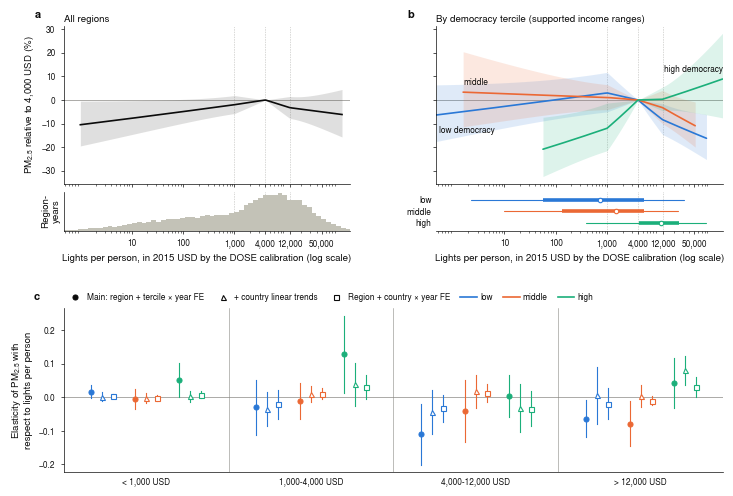

In [26]:
q = p.copy()
q['log_y'] = pl.usd_equivalent(q.log_lpc, k)
q = q.drop(columns=list(P.SEGMENTS)).join(P.spline_terms(q.log_y))
q['segment'] = P.segment(q.log_y)
print('segments unchanged:', (q.segment == p.segment).mean())
main_eq, pooled_eq = P.fit_paths(q, controls=()), P.fit_pooled(q, controls=())
fig = P.plot_paths(q, pooled_eq, {**main, 'model': main_eq['model']},
                   {'+ country trends': v1, 'country × year FE': v2})
for ax in (fig.axes[1], fig.axes[3]):
    ax.set_xlabel('Lights per person, in 2015 USD by the DOSE calibration (log scale)')
from matplotlib.ticker import FixedLocator
for ax in fig.axes[:4]:
    ax.xaxis.set_major_locator(FixedLocator([t for t in (10, 100, 1000, 4000, 12000, 50000)
                                             if ax.get_xlim()[0] <= t <= ax.get_xlim()[1]]))
# panel b: put the middle tercile's label at its left end, clear of the low tercile's right end
ax_b = fig.axes[2]
mid = next(l for l in ax_b.lines if l.get_color() == P.GROUP_COLORS[1])
for t in [t for t in ax_b.texts if t.get_text() == 'middle']:
    t.remove()
ax_b.annotate('middle', (mid.get_xdata()[0], mid.get_ydata()[0]), xytext=(0, 4), textcoords='offset points',
              ha='left', va='bottom', fontsize=6, color=P.INK)
fig.axes[4].set_ylabel('Elasticity of PM$_{2.5}$ with\nrespect to lights per person')
fig = P._save(fig, f'{P.FIGURES}/pm25_lights_paths')

### Figure: variants 3–8

Segment elasticities with respect to lights per person, by democracy tercile (rule-of-law tercile for variant 3), with 95 % intervals (country clusters). **a**, Main specification and variants 3–5. **b**, Main specification and variants 6–8. Cells with fewer than 50 regions are left out. For variants 6 and 7 the DOSE calibration's within-year R² is below 0.5 (0.39 and 0.29), so by the §3 rule their knots are the quartiles of their own measure: their segments are quartiles, not the USD ranges on the axis. Variant 7's slopes are with respect to lights per area.

Saved to `output/figures/pollution/pm25_lights_variants.{pdf,png}`.

INFO:fontTools.subset:maxp pruned


INFO:fontTools.subset:cmap pruned


INFO:fontTools.subset:post pruned


INFO:fontTools.subset:CFF  pruned


INFO:fontTools.subset:PCLT dropped


INFO:fontTools.subset:GPOS pruned


... (68 outputs left out)

INFO:fontTools.subset:CFF  pruned


INFO:fontTools.subset:GPOS pruned


INFO:fontTools.subset:GSUB pruned


INFO:fontTools.subset:name pruned


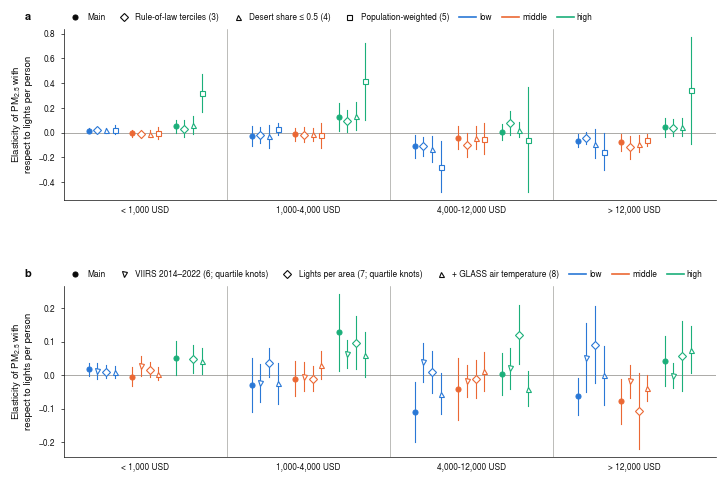

In [27]:
import matplotlib.pyplot as plt
P.nature_style()
fig, (a, b) = plt.subplots(2, 1, figsize=(183 / 25.4, 125 / 25.4),
                           gridspec_kw=dict(hspace=0.5, left=0.08, right=0.985, top=0.93, bottom=0.06))
P._slope_panel(a, {'Main': (main, 'o', True), 'Rule-of-law terciles (3)': (V['3 rule of law'], 'D', False),
                   'Desert share ≤ 0.5 (4)': (V['4 desert share <= 0.5'], '^', False),
                   'Population-weighted (5)': (V['5 pop-weighted PM2.5 + pop weights'], 's', False)}, [0, 1, 2])
P._slope_panel(b, {'Main': (main, 'o', True), 'VIIRS 2014–2022 (6; quartile knots)': (V['6 VIIRS years 2014-2022'], 'v', False),
                   'Lights per area (7; quartile knots)': (V['7 lights per area'], 'D', False),
                   '+ GLASS air temperature (8)': (V['8 + GLASS air temperature'], '^', False)}, [0, 1, 2])
for ax in (a, b):
    ax.set_ylabel('Elasticity of PM$_{2.5}$ with\nrespect to lights per person')
P._letters((a, b), (-0.06, -0.06))
fig = P._save(fig, f'{P.FIGURES}/pm25_lights_variants')